In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_students_performance.csv")

print("EDA Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

EDA Dataset Loaded Successfully!
Dataset Shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [2]:
# Dataset Information

print("DATASET INFORMATION")
print("=" * 40)

print("\nNumber of Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

DATASET INFORMATION

Number of Rows and Columns:
(1000, 8)

Column Names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB

Missing Values:
gender                         0
race/ethn

In [3]:
# Descriptive Statistical Analysis

print("DESCRIPTIVE STATISTICS")
print("=" * 40)

display(df.describe())

print("\nAverage Scores:")
print("Math Score:", df["math score"].mean())
print("Reading Score:", df["reading score"].mean())
print("Writing Score:", df["writing score"].mean())

print("\nHighest Scores:")
print(df[["math score", "reading score", "writing score"]].max())

print("\nLowest Scores:")
print(df[["math score", "reading score", "writing score"]].min())

DESCRIPTIVE STATISTICS


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



Average Scores:
Math Score: 66.089
Reading Score: 69.169
Writing Score: 68.054

Highest Scores:
math score       100
reading score    100
writing score    100
dtype: int64

Lowest Scores:
math score        0
reading score    17
writing score    10
dtype: int64


GENDER-WISE AVERAGE PERFORMANCE


,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


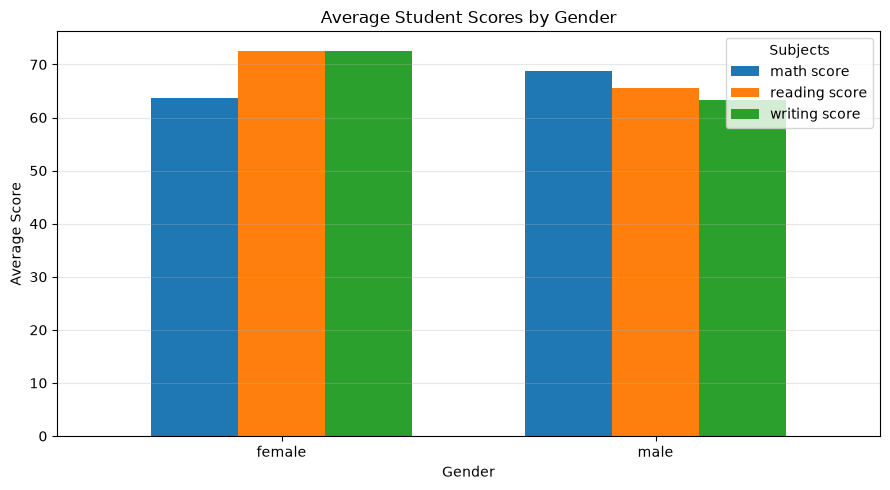

In [4]:
# Gender-wise Student Performance

gender_analysis = df.groupby("gender")[
    ["math score", "reading score", "writing score"]
].mean()

print("GENDER-WISE AVERAGE PERFORMANCE")
display(gender_analysis)

gender_analysis.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Average Student Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

PARENTAL EDUCATION ANALYSIS


,math score,reading score,writing score
parental level of education,,,
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
high school,62.137755,64.704082,62.448980
master's degree,69.745763,75.372881,75.677966
some college,67.128319,69.460177,68.840708
some high school,63.497207,66.938547,64.888268


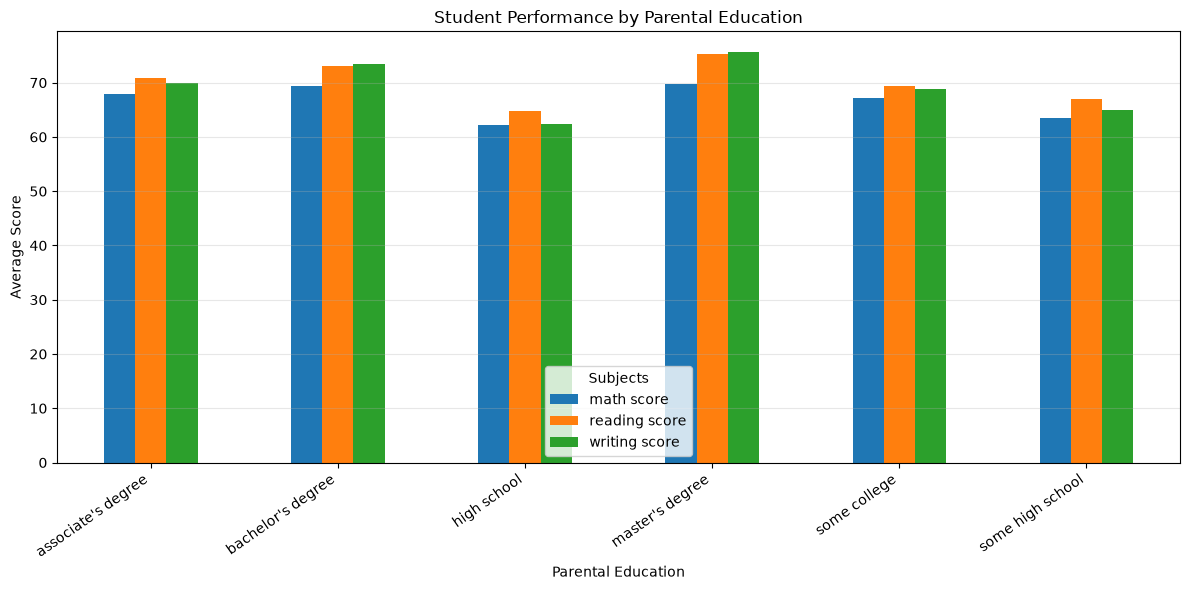

In [5]:
parent_analysis = df.groupby(
    "parental level of education"
)[["math score", "reading score", "writing score"]].mean()

print("PARENTAL EDUCATION ANALYSIS")
display(parent_analysis)

parent_analysis.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Student Performance by Parental Education")
plt.xlabel("Parental Education")
plt.ylabel("Average Score")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Subjects")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

LUNCH TYPE PERFORMANCE


,math score,reading score,writing score
lunch,,,
free/reduced,58.921127,64.653521,63.022535
standard,70.034109,71.654264,70.823256


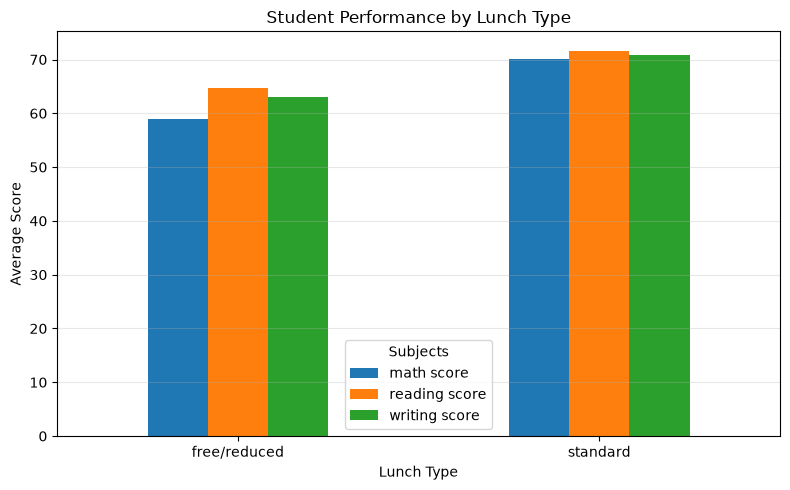

In [6]:
lunch_analysis = df.groupby("lunch")[
    ["math score", "reading score", "writing score"]
].mean()

print("LUNCH TYPE PERFORMANCE")
display(lunch_analysis)

lunch_analysis.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Student Performance by Lunch Type")
plt.xlabel("Lunch Type")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

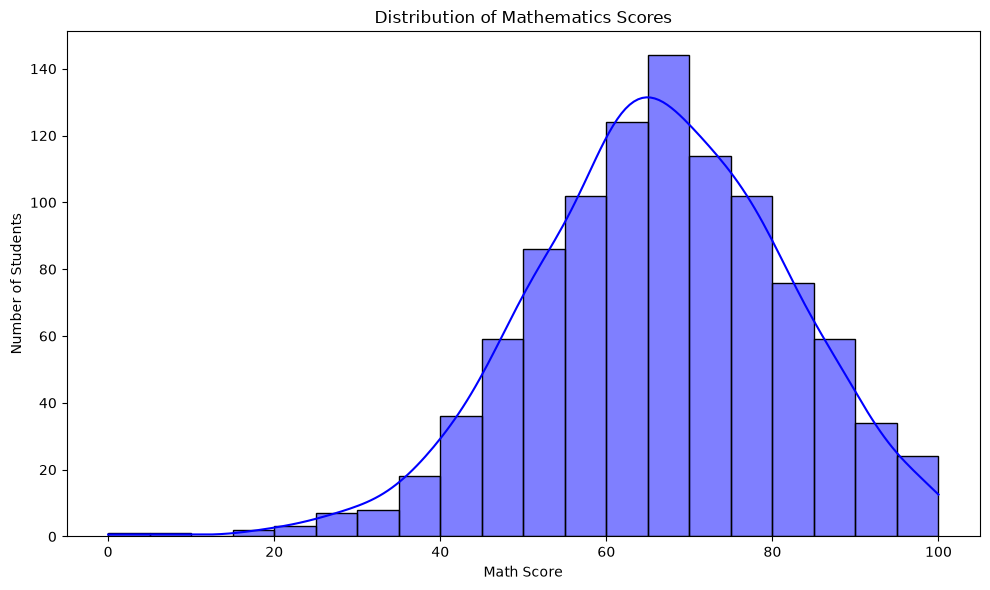

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="math score",
    color="blue",
    kde=True,
    bins=20
)

plt.title("Distribution of Mathematics Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

CORRELATION MATRIX


,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


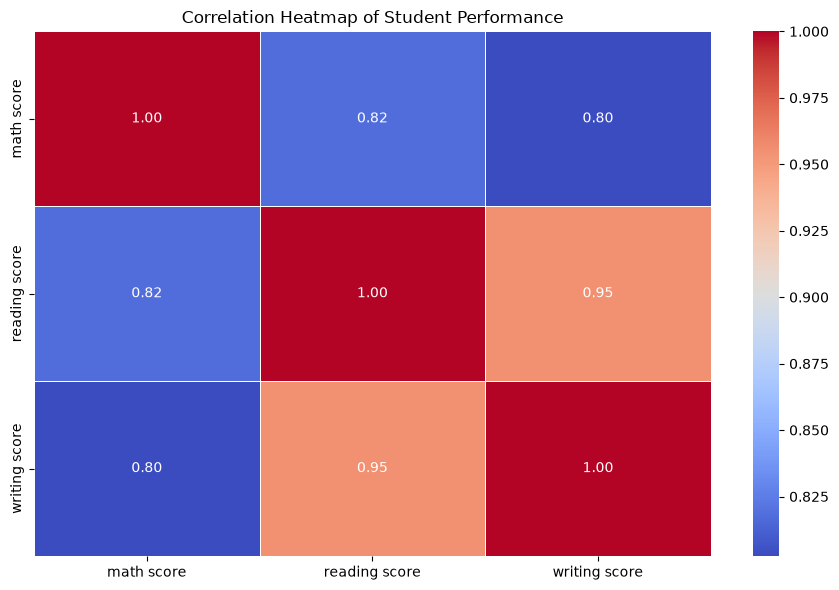

In [8]:
# Correlation Analysis

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

print("CORRELATION MATRIX")
display(correlation)

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Performance")
plt.tight_layout()
plt.show()

PERFORMANCE BASED ON TEST PREPARATION


,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


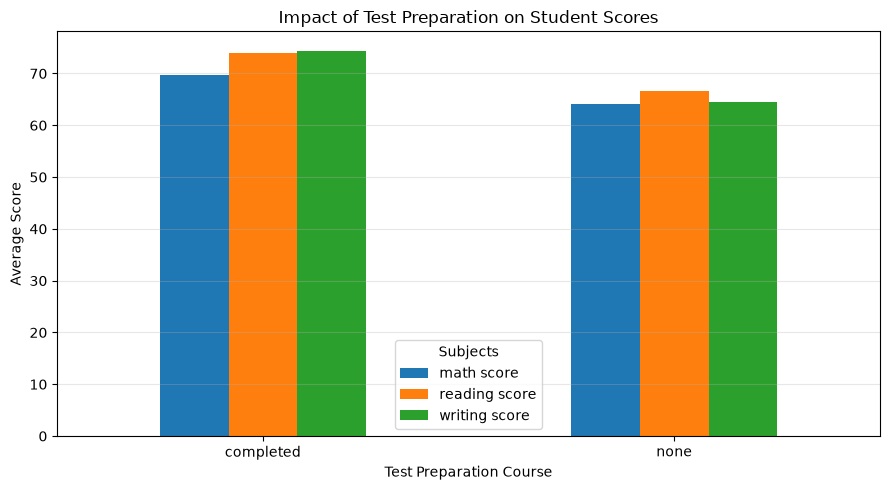

In [9]:
# Test Preparation Course Analysis

test_analysis = df.groupby("test preparation course")[
    ["math score", "reading score", "writing score"]
].mean()

print("PERFORMANCE BASED ON TEST PREPARATION")
display(test_analysis)

test_analysis.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Impact of Test Preparation on Student Scores")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

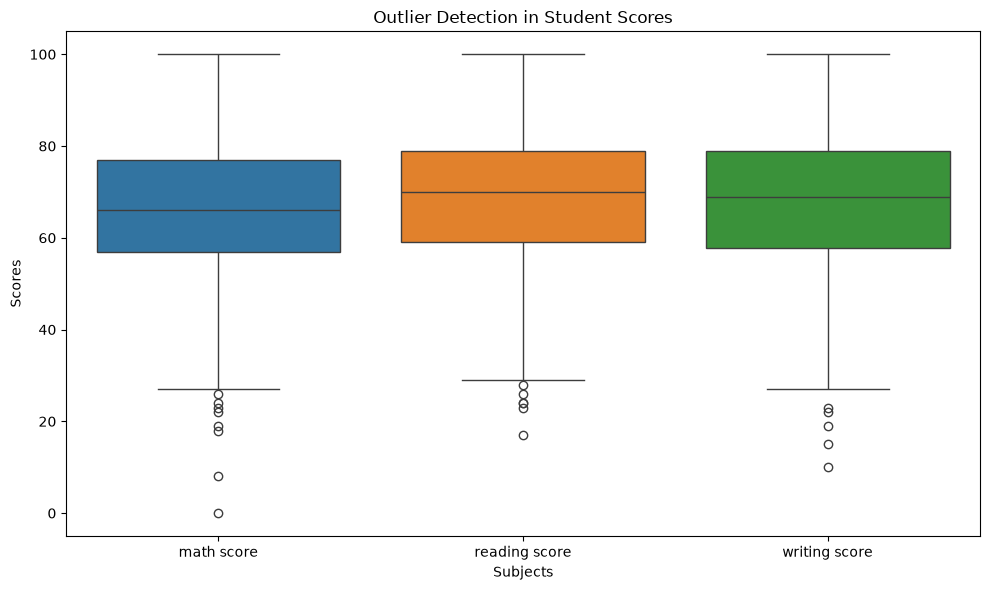

In [10]:
# Outlier Detection using Boxplots

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[["math score", "reading score", "writing score"]]
)

plt.title("Outlier Detection in Student Scores")
plt.xlabel("Subjects")
plt.ylabel("Scores")
plt.tight_layout()
plt.show()

In [11]:
# Calculate Overall Average Score

df["average score"] = df[
    ["math score", "reading score", "writing score"]
].mean(axis=1)

print("OVERALL STUDENT PERFORMANCE")

print("\nAverage Student Score:")
print(round(df["average score"].mean(), 2))

print("\nHighest Student Average:")
print(round(df["average score"].max(), 2))

print("\nLowest Student Average:")
print(round(df["average score"].min(), 2))

print("\nPerformance Categories:")

df["performance"] = pd.cut(
    df["average score"],
    bins=[-1, 40, 60, 80, 100],
    labels=["Low", "Average", "Good", "Excellent"]
)

display(df["performance"].value_counts())

OVERALL STUDENT PERFORMANCE

Average Student Score:
67.77

Highest Student Average:
100.0

Lowest Student Average:
9.0

Performance Categories:


performance
Good         513
Average      261
Excellent    194
Low           32
Name: count, dtype: int64

In [12]:
# Save EDA Dataset

df.to_csv("student_performance_eda_results.csv", index=False)

print("EDA results saved successfully!")

EDA results saved successfully!


In [13]:
# Five Key Insights from Student Performance Dataset

print("FIVE KEY INSIGHTS")
print("=" * 50)

# 1. Gender-wise performance
gender_result = df.groupby("gender")["average score"].mean()
print("\n1. Gender-wise Average Performance:")
print(gender_result.round(2))

# 2. Parental education
parent_result = df.groupby(
    "parental level of education"
)["average score"].mean()

print("\n2. Performance by Parental Education:")
print(parent_result.round(2))

# 3. Lunch type
lunch_result = df.groupby("lunch")["average score"].mean()
print("\n3. Performance by Lunch Type:")
print(lunch_result.round(2))

# 4. Test preparation
test_result = df.groupby(
    "test preparation course"
)["average score"].mean()

print("\n4. Test Preparation Impact:")
print(test_result.round(2))

# 5. Subject correlation
print("\n5. Subject Correlation:")
print(
    df[["math score", "reading score", "writing score"]]
    .corr().round(2)
)

print("\nOverall Average Score:",
      round(df["average score"].mean(), 2))

FIVE KEY INSIGHTS

1. Gender-wise Average Performance:
gender
female    69.57
male      65.84
Name: average score, dtype: float64

2. Performance by Parental Education:
parental level of education
associate's degree    69.57
bachelor's degree     71.92
high school           63.10
master's degree       73.60
some college          68.48
some high school      65.11
Name: average score, dtype: float64

3. Performance by Lunch Type:
lunch
free/reduced    62.20
standard        70.84
Name: average score, dtype: float64

4. Test Preparation Impact:
test preparation course
completed    72.67
none         65.04
Name: average score, dtype: float64

5. Subject Correlation:
               math score  reading score  writing score
math score           1.00           0.82           0.80
reading score        0.82           1.00           0.95
writing score        0.80           0.95           1.00

Overall Average Score: 67.77


In [14]:
df.to_csv("student_performance_eda_results.csv", index=False)

print("Final EDA dataset saved successfully!")

Final EDA dataset saved successfully!


# Conclusion

Exploratory Data Analysis was successfully performed on the Students Performance dataset containing 1,000 records and 8 original columns.

The analysis included:

- Dataset overview and descriptive statistics.
- Missing value and duplicate record inspection.
- Gender-wise performance analysis.
- Parental education and lunch type analysis.
- Test preparation course analysis.
- Subject score distribution visualization.
- Correlation heatmap.
- Outlier detection.
- Overall student performance analysis.

Python libraries such as Pandas, NumPy, Matplotlib and Seaborn were used for data analysis and visualization.

The analysis helped identify patterns, relationships and factors associated with student academic performance.

This project improved my practical understanding of data analysis, visualization and extracting meaningful insights from raw datasets.